# HGQ2 Layer Bitwidth Distributions

This notebook inspects the learned **integer bits (`i`)** and **fractional bits (`f`)** from the HGQ2 layers across all specialist models in:

`/mnt/d/data/neuralnet_jobs/hgq2-run3-optimal-threshold-fit`

For each HGQ2 `QDense` layer, we extract the effective `kif` bitwidths (`k`: sign bit, `i`: integer bits, `f`: fractional bits) from:
- **`kq`**: Kernel (weight) quantizer
- **`bq`**: Bias quantizer
- **`iq`**: Input quantizer

In [1]:
import os

os.environ.setdefault("KERAS_BACKEND", "tensorflow")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from utils import add_project_root_to_sys_path

add_project_root_to_sys_path()

from neuralnet.models.committee import BinnedSpecialistCommittee

JOB_DIR = Path("/mnt/d/data/neuralnet_jobs/hgq2-run3-optimal-threshold-fit")
QUANTIZER_LABELS = {
    "kq": "Kernel (kq)",
    "bq": "Bias (bq)",
    "iq": "Input (iq)",
}

In [2]:
# Load the specialist committee (all operating-point JSONs reference the same 25 specialist models)
committee = BinnedSpecialistCommittee.from_json(JOB_DIR, op_point="tight")
print(f"Loaded {len(committee.models)} specialist models from {JOB_DIR}")

records = []
for model_idx, specialist in enumerate(committee.models):
    member_id = specialist.training_results.get("id", model_idx) if specialist.training_results else model_idx
    for layer in specialist.keras_model.layers:
        for q_name in ("kq", "bq", "iq", "oq"):
            q = getattr(layer, q_name, None)
            if q is None or not hasattr(q, "quantizer"):
                continue
            k, i, f = q.quantizer.kif
            k_arr = np.asarray(k).ravel()
            i_arr = np.asarray(i).ravel()
            f_arr = np.asarray(f).ravel()
            records.append(
                pl.DataFrame(
                    {
                        "member_id": np.full(i_arr.shape, member_id, dtype=np.int64),
                        "layer": [layer.name] * len(i_arr),
                        "quantizer": [q_name] * len(i_arr),
                        "sign_bits": k_arr.astype(np.float64),
                        "integer_bits": i_arr.astype(np.float64),
                        "fractional_bits": f_arr.astype(np.float64),
                        "total_bits": (k_arr + i_arr + f_arr).astype(np.float64),
                    }
                )
            )

bits_df = pl.concat(records)
print(f"Extracted {bits_df.height:,} bitwidth entries.")
bits_df.head()

2026-11-23 23:50:45.768288: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-23 23:50:45.768566: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-23 23:50:45.809936: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-23 23:50:46.686230: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

Loaded 25 specialist models from /mnt/d/data/neuralnet_jobs/hgq2-run3-optimal-threshold-fit
Extracted 7,900 bitwidth entries.


member_id,layer,quantizer,sign_bits,integer_bits,fractional_bits,total_bits
i64,str,str,f64,f64,f64,f64
172,"""q_dense""","""kq""",1.0,1.0,1.0,3.0
172,"""q_dense""","""kq""",1.0,0.0,0.0,1.0
172,"""q_dense""","""kq""",1.0,2.0,1.0,4.0
172,"""q_dense""","""kq""",1.0,2.0,1.0,4.0
172,"""q_dense""","""kq""",1.0,1.0,1.0,3.0


In [3]:
summary_df = (
    bits_df.group_by(["layer", "quantizer"], maintain_order=True)
    .agg(
        pl.len().alias("count"),
        pl.col("integer_bits").min().alias("i_min"),
        pl.col("integer_bits").mean().round(2).alias("i_mean"),
        pl.col("integer_bits").median().alias("i_median"),
        pl.col("integer_bits").max().alias("i_max"),
        pl.col("fractional_bits").min().alias("f_min"),
        pl.col("fractional_bits").mean().round(2).alias("f_mean"),
        pl.col("fractional_bits").median().alias("f_median"),
        pl.col("fractional_bits").max().alias("f_max"),
    )
)
summary_df

layer,quantizer,count,i_min,i_mean,i_median,i_max,f_min,f_mean,f_median,f_max
str,str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""q_dense""","""kq""",6250,0.0,2.14,1.0,7.0,0.0,5.97,5.0,15.0
"""q_dense""","""bq""",125,-6.0,-0.1,0.0,3.0,0.0,7.27,6.0,15.0
"""q_dense""","""iq""",1250,-5.0,-1.73,-2.0,21.0,-21.0,3.97,4.0,8.0
"""q_dense_1""","""kq""",125,0.0,3.41,3.0,7.0,0.0,5.6,4.0,15.0
"""q_dense_1""","""bq""",25,-2.0,0.64,1.0,3.0,2.0,5.96,4.0,15.0
"""q_dense_1""","""iq""",125,-4.0,0.63,1.0,3.0,-1.0,4.35,5.0,6.0


## Distributions by Layer and Quantizer

Each row shows a `(layer, quantizer)` pair across all 25 specialist models, with integer bits (`i`) on the left and fractional bits (`f`) on the right.

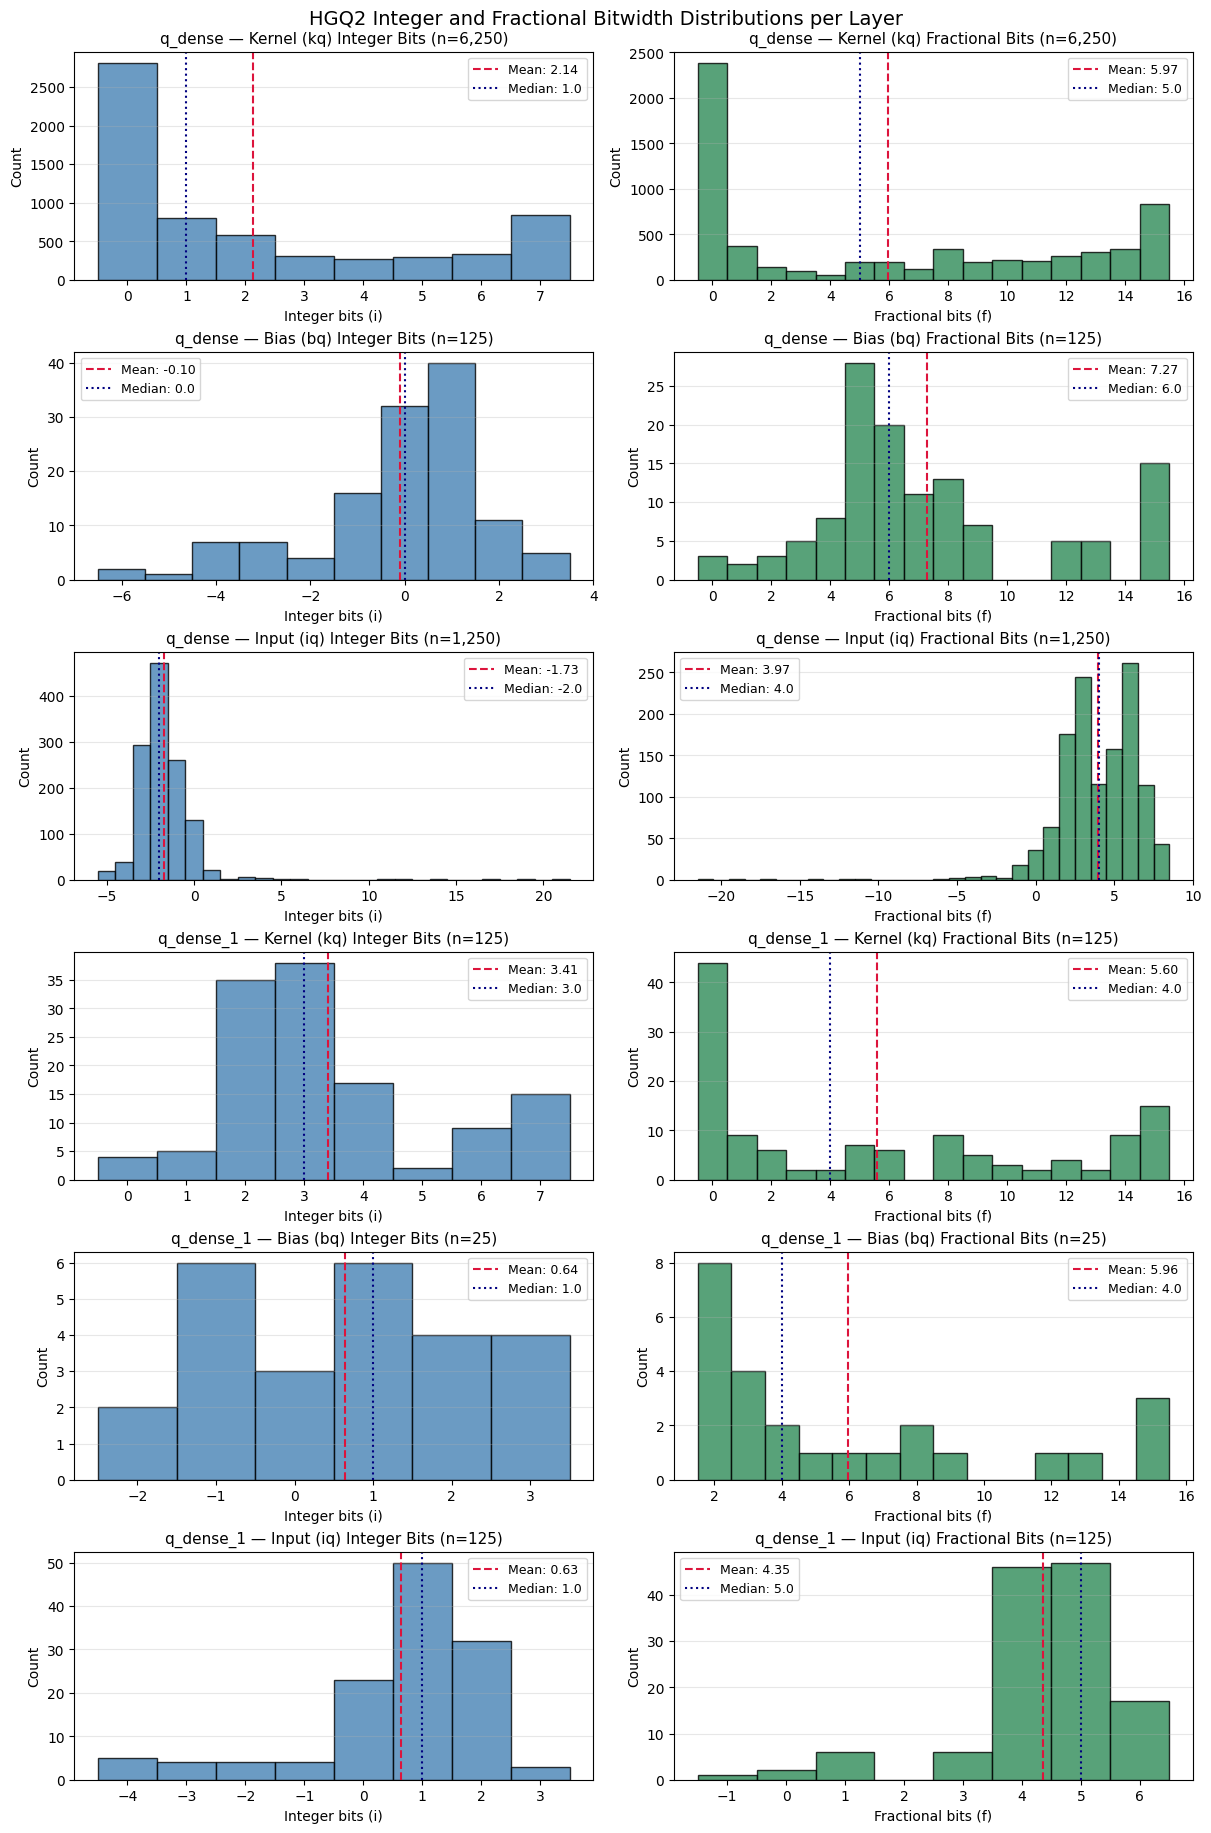

In [4]:
def plot_integer_hist(ax, values: np.ndarray, color: str, xlabel: str, title: str) -> None:
    vmin = int(np.floor(values.min()))
    vmax = int(np.ceil(values.max()))
    bins = np.arange(vmin - 0.5, vmax + 1.5, 1.0)

    ax.hist(values, bins=bins, color=color, edgecolor="black", alpha=0.8)
    mean_val = float(np.mean(values))
    med_val = float(np.median(values))
    ax.axvline(mean_val, color="crimson", linestyle="--", linewidth=1.5, label=f"Mean: {mean_val:.2f}")
    ax.axvline(med_val, color="navy", linestyle=":", linewidth=1.5, label=f"Median: {med_val:.1f}")

    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=9)


layers = bits_df["layer"].unique(maintain_order=True).to_list()
quantizers = bits_df["quantizer"].unique(maintain_order=True).to_list()
pairs = [
    (layer, q)
    for layer in layers
    for q in quantizers
    if bits_df.filter((pl.col("layer") == layer) & (pl.col("quantizer") == q)).height > 0
]

fig, axes = plt.subplots(len(pairs), 2, figsize=(12, 3.0 * len(pairs)), constrained_layout=True)
if len(pairs) == 1:
    axes = np.array([axes])

for row_idx, (layer, q) in enumerate(pairs):
    sub = bits_df.filter((pl.col("layer") == layer) & (pl.col("quantizer") == q))
    q_label = QUANTIZER_LABELS.get(q, q)
    n_vals = sub.height

    plot_integer_hist(
        axes[row_idx, 0],
        sub["integer_bits"].to_numpy(),
        color="steelblue",
        xlabel="Integer bits (i)",
        title=f"{layer} — {q_label} Integer Bits (n={n_vals:,})",
    )
    plot_integer_hist(
        axes[row_idx, 1],
        sub["fractional_bits"].to_numpy(),
        color="seagreen",
        xlabel="Fractional bits (f)",
        title=f"{layer} — {q_label} Fractional Bits (n={n_vals:,})",
    )

fig.suptitle("HGQ2 Integer and Fractional Bitwidth Distributions per Layer", fontsize=14, y=1.01)
plt.show()

## Aggregated Distributions Across All HGQ Layers

Combined distributions across all layers for each quantizer type (`kq`, `bq`, `iq`).

/tmp/ipykernel_55035/2021644787.py:26: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


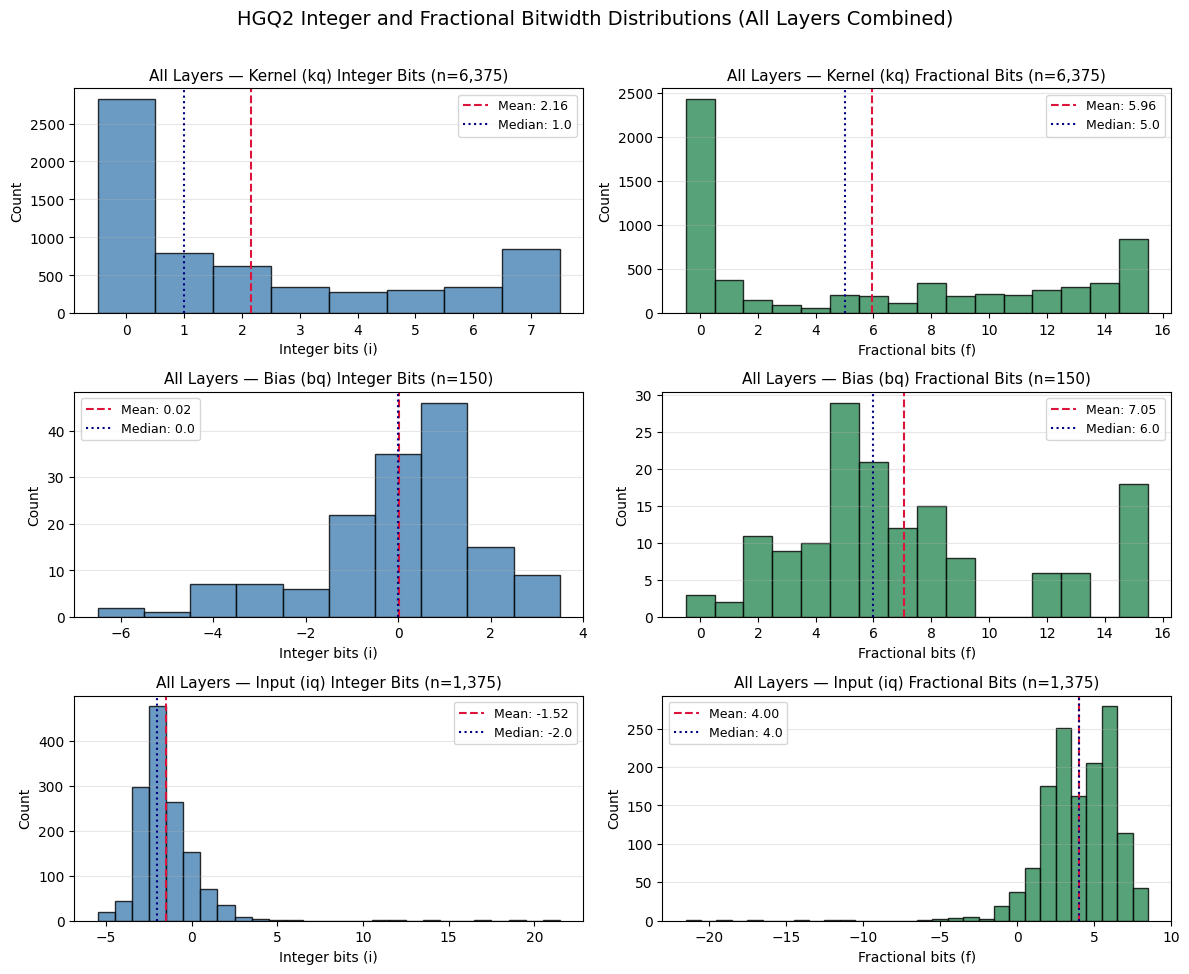

In [5]:
fig, axes = plt.subplots(len(quantizers), 2, figsize=(12, 3.2 * len(quantizers)), constrained_layout=True)
if len(quantizers) == 1:
    axes = np.array([axes])

for row_idx, q in enumerate(quantizers):
    sub = bits_df.filter(pl.col("quantizer") == q)
    q_label = QUANTIZER_LABELS.get(q, q)
    n_vals = sub.height

    plot_integer_hist(
        axes[row_idx, 0],
        sub["integer_bits"].to_numpy(),
        color="steelblue",
        xlabel="Integer bits (i)",
        title=f"All Layers — {q_label} Integer Bits (n={n_vals:,})",
    )
    plot_integer_hist(
        axes[row_idx, 1],
        sub["fractional_bits"].to_numpy(),
        color="seagreen",
        xlabel="Fractional bits (f)",
        title=f"All Layers — {q_label} Fractional Bits (n={n_vals:,})",
    )

fig.suptitle("HGQ2 Integer and Fractional Bitwidth Distributions (All Layers Combined)", fontsize=14, y=1.01)
fig.tight_layout()
plt.show()